In [48]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import permutation_test

In [31]:
# data

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data" / "processed"

market = pd.read_csv(DATA_DIR / "market_daily.csv", parse_dates=["date"])

print("Shape:", market.shape)
print("\nColumns:")
print(market.columns.tolist())

print("\nFirst 5 rows:")
display(market.head())

print("\nLast 5 rows:")
display(market.tail())

print("\nData types:")
display(market.dtypes.to_frame("dtype"))

Shape: (19504, 65)

Columns:
['date', 'spx_open', 'spx_high', 'spx_low', 'spx_close', 'spx_volume', 'dji_open', 'dji_high', 'dji_low', 'dji_close', 'dji_volume', 'nasdaq_open', 'nasdaq_high', 'nasdaq_low', 'nasdaq_close', 'nasdaq_volume', 'qqq_open', 'qqq_high', 'qqq_low', 'qqq_close', 'qqq_volume', 'qqq_n_minutes', 'spy_open', 'spy_high', 'spy_low', 'spy_close', 'spy_volume', 'spy_n_minutes', 'vix_close', 'vix_log_change', 'spx_log_return', 'spx_simple_return', 'spx_rv_5d', 'spx_rv_21d', 'spx_rv_63d', 'spx_volatility_21d_ann', 'spx_intraday_range', 'dji_log_return', 'dji_simple_return', 'dji_rv_5d', 'dji_rv_21d', 'dji_rv_63d', 'dji_volatility_21d_ann', 'dji_intraday_range', 'nasdaq_log_return', 'nasdaq_simple_return', 'nasdaq_rv_5d', 'nasdaq_rv_21d', 'nasdaq_rv_63d', 'nasdaq_volatility_21d_ann', 'nasdaq_intraday_range', 'qqq_log_return', 'qqq_simple_return', 'qqq_rv_5d', 'qqq_rv_21d', 'qqq_rv_63d', 'qqq_volatility_21d_ann', 'qqq_intraday_range', 'spy_log_return', 'spy_simple_return', 

,date,spx_open,spx_high,spx_low,spx_close,spx_volume,dji_open,dji_high,dji_low,dji_close,...,qqq_rv_63d,qqq_volatility_21d_ann,qqq_intraday_range,spy_log_return,spy_simple_return,spy_rv_5d,spy_rv_21d,spy_rv_63d,spy_volatility_21d_ann,spy_intraday_range
0,1949-07-12,NaN,NaN,NaN,NaN,NaN,171.78,171.96,170.52,171.78,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1949-07-13,NaN,NaN,NaN,NaN,NaN,173.24,173.34,171.59,173.24,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1949-07-14,NaN,NaN,NaN,NaN,NaN,173.59,174.02,172.47,173.59,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1949-07-15,NaN,NaN,NaN,NaN,NaN,173.48,173.89,172.64,173.48,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1949-07-18,NaN,NaN,NaN,NaN,NaN,174.04,174.40,173.20,174.04,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Last 5 rows:


,date,spx_open,spx_high,spx_low,spx_close,spx_volume,dji_open,dji_high,dji_low,dji_close,...,qqq_rv_63d,qqq_volatility_21d_ann,qqq_intraday_range,spy_log_return,spy_simple_return,spy_rv_5d,spy_rv_21d,spy_rv_63d,spy_volatility_21d_ann,spy_intraday_range
19499,2026-10-21,7736.43,7770.40,7709.34,7757.17,2.889475e+09,52658.2653,52865.2860,52397.2392,52861.2956,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
19500,2026-10-22,7694.62,7702.94,7637.36,7663.43,3.559453e+09,52793.2788,52933.2928,52513.2508,52873.2768,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
19501,2026-10-23,7637.18,7660.15,7612.07,7623.68,2.749563e+09,52702.2697,52702.2697,52060.2055,52220.2115,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
19502,2026-10-26,7639.70,7702.13,7639.70,7676.77,2.759067e+09,52325.2320,52625.2620,52268.2263,52367.2262,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
19503,2026-10-27,7699.47,7736.24,7677.16,7722.60,2.810939e+09,52282.2277,52483.2478,52237.2232,52383.2478,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Data types:


,dtype
date,datetime64[us]
spx_open,float64
spx_high,float64
spx_low,float64
spx_close,float64
...,...
spy_rv_5d,float64
spy_rv_21d,float64
spy_rv_63d,float64
spy_volatility_21d_ann,float64


In [32]:
print("Duplicate dates:", market["date"].duplicated().sum())
print("Date range:", market["date"].min(), "to", market["date"].max())

missing = (
    market.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
)

missing["missing_pct"] = (
    missing["missing_count"] / len(market) * 100
).round(2)

display(missing.head(25))

Duplicate dates: 0
Date range: 1949-07-12 00:00:00 to 2026-10-27 00:00:00


,missing_count,missing_pct
dji_volume,19504,100.00
qqq_rv_63d,14840,76.09
qqq_rv_21d,14714,75.44
qqq_volatility_21d_ann,14714,75.44
qqq_rv_5d,14666,75.19
qqq_log_return,14654,75.13
qqq_simple_return,14654,75.13
qqq_volume,14651,75.12
qqq_open,14651,75.12
qqq_high,14651,75.12


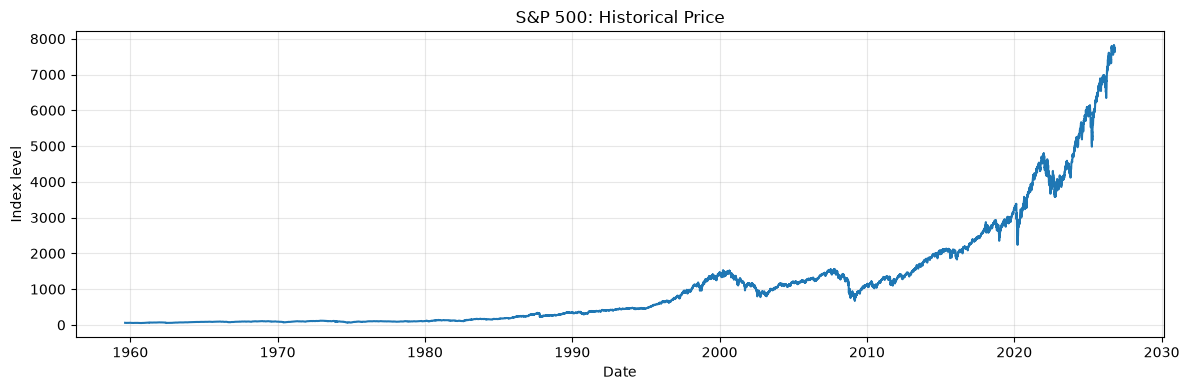

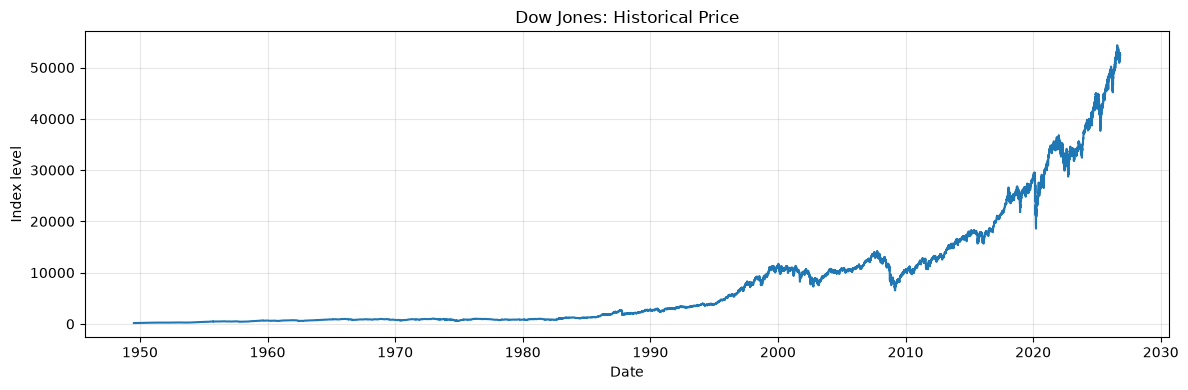

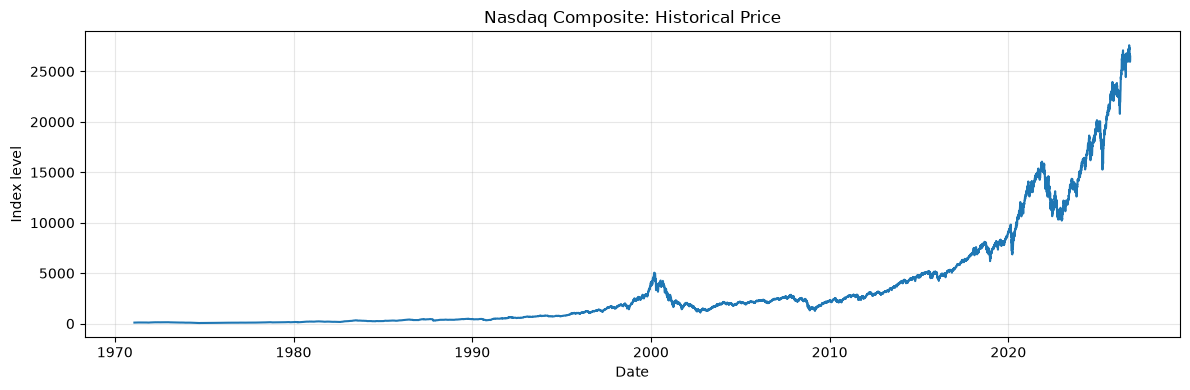

In [35]:
DATA_DIR = Path.cwd() / "data" / "processed"
market = pd.read_csv(DATA_DIR / "market_daily.csv", parse_dates=["date"])
market = market.sort_values("date")

assets = {
    "S&P 500": "spx_close",
    "Dow Jones": "dji_close",
    "Nasdaq Composite": "nasdaq_close",
}

for name, col in assets.items():
    prices = market.set_index("date")[col].dropna()

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(prices.index, prices)
    ax.set_title(f"{name}: Historical Price")
    ax.set_xlabel("Date")
    ax.set_ylabel("Index level")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [36]:
returns = pd.DataFrame({"date": market["date"]})

for asset, col in {
    "spx": "spx_close",
    "dji": "dji_close",
    "nasdaq": "nasdaq_close",
}.items():
    prices = market[["date", col]].dropna().sort_values("date")
    prices[f"{asset}_log_return"] = np.log(
        prices[col] / prices[col].shift(1)
    )

    returns = returns.merge(
        prices[["date", f"{asset}_log_return"]],
        on="date",
        how="left",
        validate="one_to_one",
    )

print("Daily log-return summary:")
display(returns.drop(columns="date").describe().T)

Daily log-return summary:


,count,mean,std,min,25%,50%,75%,max
spx_log_return,16937.0,0.000288,0.010314,-0.228868,-0.004243,0.000465,0.005205,0.109572
dji_log_return,19446.0,0.000294,0.009810,-0.256325,-0.004283,0.000467,0.005146,0.107643
nasdaq_log_return,14048.0,0.000397,0.012672,-0.131492,-0.004614,0.001067,0.006263,0.132546


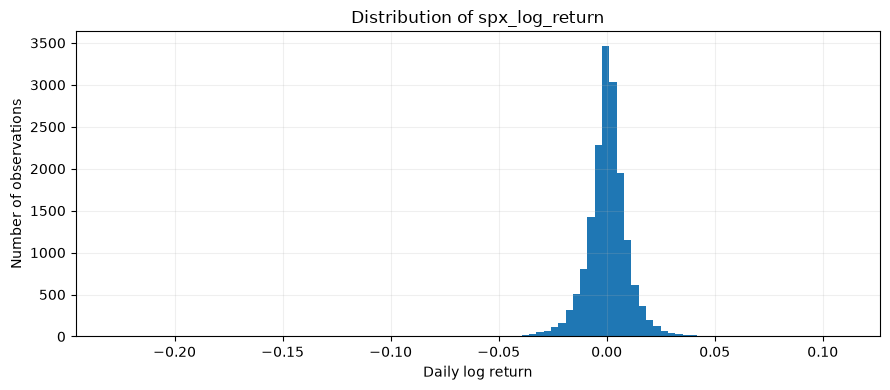

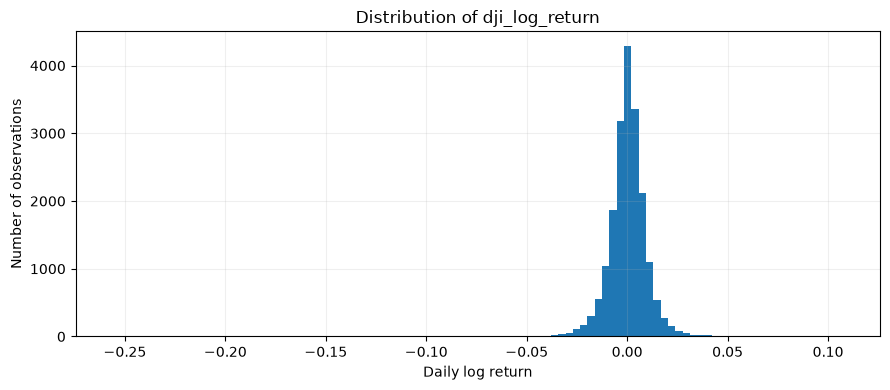

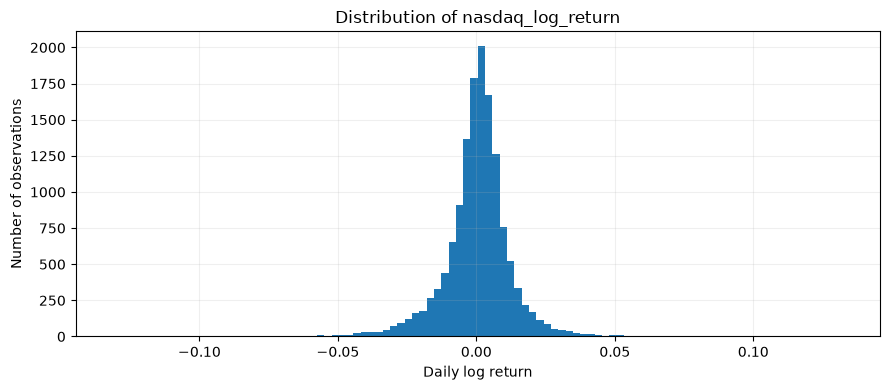

,mean,std,min,max,skew
spx_log_return,0.000288,0.010314,-0.228868,0.109572,-0.936160
dji_log_return,0.000294,0.009810,-0.256325,0.107643,-1.167190
nasdaq_log_return,0.000397,0.012672,-0.131492,0.132546,-0.329686


In [37]:
return_cols = [
    "spx_log_return",
    "dji_log_return",
    "nasdaq_log_return",
]

for col in return_cols:
    x = returns[col].dropna()

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.hist(x, bins=100)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel("Daily log return")
    ax.set_ylabel("Number of observations")
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

display(
    returns[return_cols].agg(
        ["mean", "std", "min", "max", "skew"]
    ).T
)

In [38]:
market = pd.read_csv(
    "data/processed/market_daily.csv",
    parse_dates=["date"]
)

elections = pd.read_csv(
    "data/processed/election_events.csv",
    parse_dates=["election_date"]
)

# Build a clean S&P 500 daily series.
spx = (
    market[["date", "spx_close"]]
    .dropna()
    .sort_values("date")
    .drop_duplicates("date")
    .reset_index(drop=True)
)

spx["log_return"] = np.log(
    spx["spx_close"] / spx["spx_close"].shift(1)
)

spx = spx.dropna(subset=["log_return"]).reset_index(drop=True)

print("S&P 500 date range:", spx["date"].min(), "to", spx["date"].max())
print("Number of midterm elections:", len(elections))

S&P 500 date range: 1959-08-26 00:00:00 to 2026-10-27 00:00:00
Number of midterm elections: 16


In [45]:
results = []

for _, election in elections.iterrows():
    election_date = election["election_date"]

    # Trading observations strictly before Election Day.
    pre = spx.loc[spx["date"] < election_date]

    # Observations strictly after Election Day.
    post = spx.loc[spx["date"] > election_date]

    # Exact Election Day observation, if available.
    event = spx.loc[spx["date"] == election_date]

    if len(pre) < 20 or len(post) < 60:
        continue

    row = {
        "election_year": int(election["election_year"]),
        "election_date": election_date,
        "exact_election_session_available": not event.empty,
    }

    # Pre-election: last 20 trading-session returns.
    pre_returns = pre["log_return"].tail(20)
    row["pre_20d_return_pct"] = np.expm1(pre_returns.sum()) * 100
    row["pre_20d_rv_pct"] = np.sqrt((pre_returns ** 2).sum()) * 100

    # Election-day return only when that date exists in the data.
    if not event.empty:
        event_return = event["log_return"].iloc[0]
        row["election_day_return_pct"] = np.expm1(event_return) * 100
        row["election_day_rv_pct"] = abs(event_return) * 100
    else:
        row["election_day_return_pct"] = np.nan
        row["election_day_rv_pct"] = np.nan

    # Post-election: sessions strictly after Election Day.
    for n in [5, 20, 60]:
        window_returns = post["log_return"].head(n)

        row[f"post_{n}d_return_pct"] = (
            np.expm1(window_returns.sum()) * 100
        )
        row[f"post_{n}d_rv_pct"] = (
            np.sqrt((window_returns ** 2).sum()) * 100
        )

    results.append(row)

event_study = (
    pd.DataFrame(results)
    .sort_values("election_year")
    .reset_index(drop=True)
)

display(event_study.round(3))


C:\Users\JM2090\AppData\Local\Temp\ipykernel_25092\4173436586.py:57: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(event_study.round(3))


,election_year,election_date,exact_election_session_available,pre_20d_return_pct,pre_20d_rv_pct,election_day_return_pct,election_day_rv_pct,post_5d_return_pct,post_5d_rv_pct,post_20d_return_pct,post_20d_rv_pct,post_60d_return_pct,post_60d_rv_pct
0,1962,1962-11-06,False,2.243,5.763,NaN,NaN,1.902,1.833,6.924,3.306,13.642,4.732
1,1966,1966-11-08,False,8.319,3.950,NaN,NaN,1.189,1.296,1.226,2.980,8.213,4.598
2,1970,1970-11-03,True,-3.423,2.686,0.850,0.847,0.677,0.695,5.058,3.115,13.845,4.360
3,1974,1974-11-05,True,12.517,8.926,2.778,2.740,-1.917,2.197,-10.252,6.018,2.490,10.229
4,1978,1978-11-07,True,-8.987,6.155,-1.408,1.418,-1.449,2.017,3.879,3.948,6.020,6.154
5,1982,1982-11-02,True,11.490,7.789,1.499,1.487,4.022,4.475,0.756,8.333,3.091,11.028
6,1986,1986-11-04,True,4.694,3.032,0.163,0.163,0.357,0.528,3.107,4.552,11.324,7.339
7,1990,1990-11-06,True,0.354,6.211,-0.944,0.949,1.941,3.328,5.873,4.600,10.086,7.654
8,1994,1994-11-08,True,0.876,3.206,0.559,0.558,-0.133,0.960,-3.097,2.814,3.337,4.217
9,1998,1998-11-03,True,12.446,6.197,-0.068,0.068,1.568,1.903,5.438,4.358,14.601,9.163


In [43]:
return_columns = [
    "pre_20d_return_pct",
    "election_day_return_pct",
    "post_5d_return_pct",
    "post_20d_return_pct",
    "post_60d_return_pct",
]

rv_columns = [
    "pre_20d_rv_pct",
    "election_day_rv_pct",
    "post_5d_rv_pct",
    "post_20d_rv_pct",
    "post_60d_rv_pct",
]

print("RETURN SUMMARY")
display(
    event_study[return_columns]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .T.round(3)
)

print("REALIZED VOLATILITY SUMMARY")
display(
    event_study[rv_columns]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .T.round(3)
)

RETURN SUMMARY


,count,mean,median,std,min,max
pre_20d_return_pct,16.0,4.096,3.431,6.804,-8.987,15.672
election_day_return_pct,14.0,0.436,0.560,1.011,-1.408,2.778
post_5d_return_pct,16.0,0.716,0.970,2.051,-3.545,4.275
post_20d_return_pct,16.0,1.629,2.469,4.198,-10.252,6.924
post_60d_return_pct,16.0,6.216,6.477,5.744,-6.017,14.601


REALIZED VOLATILITY SUMMARY


,count,mean,median,std,min,max
pre_20d_rv_pct,16.0,5.462,5.959,2.230,2.150,9.160
election_day_rv_pct,14.0,0.819,0.698,0.698,0.068,2.740
post_5d_rv_pct,16.0,2.222,1.960,1.518,0.528,5.994
post_20d_rv_pct,16.0,4.541,4.455,1.923,1.560,8.333
post_60d_rv_pct,16.0,7.361,7.031,2.744,3.522,11.150


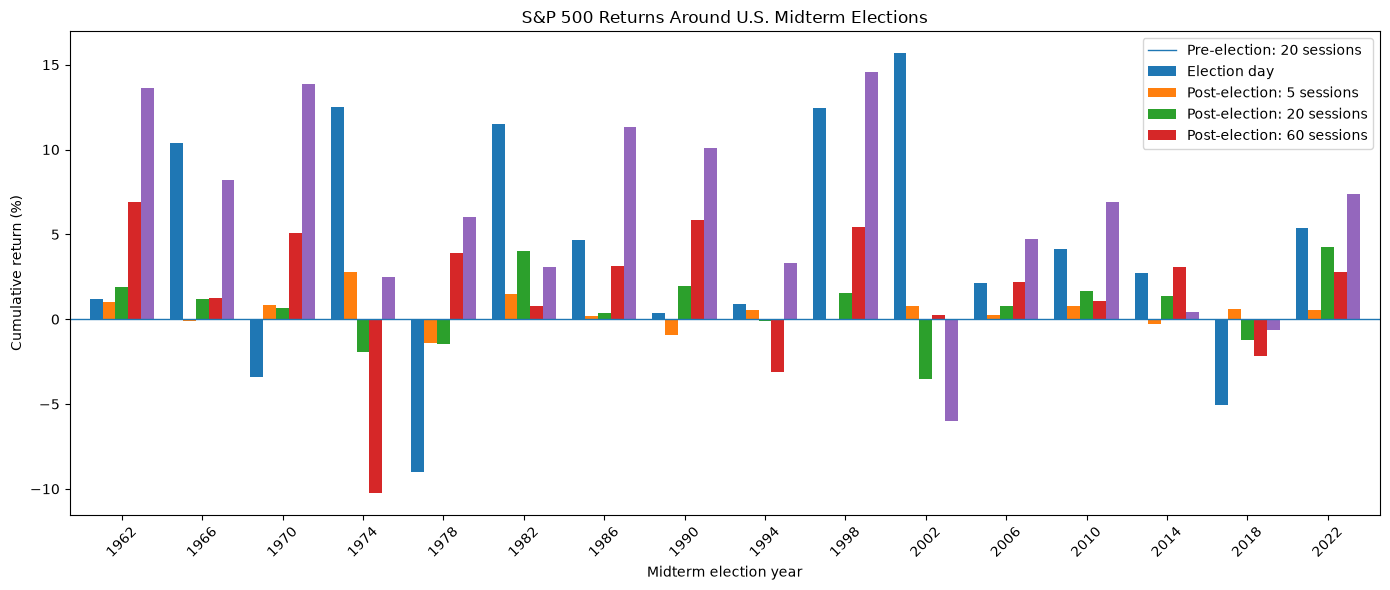

In [41]:
plot_data = event_study.set_index("election_year")[return_columns]

ax = plot_data.plot(
    kind="bar",
    figsize=(14, 6),
    width=0.8
)

ax.axhline(0, linewidth=1)
ax.set_title("S&P 500 Returns Around U.S. Midterm Elections")
ax.set_xlabel("Midterm election year")
ax.set_ylabel("Cumulative return (%)")
ax.legend(
    ["Pre-election: 20 sessions",
     "Election day",
     "Post-election: 5 sessions",
     "Post-election: 20 sessions",
     "Post-election: 60 sessions"],
    loc="best"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [46]:

# Compare midterm windows with ordinary market windows of equal length.

window_specs = {
    "pre_20d": (-20, -1, 20),
    "post_5d": (1, 5, 5),
    "post_20d": (1, 20, 20),
    "post_60d": (1, 60, 60),
}

# Calculate cumulative returns for every possible window of each length.
daily_returns = spx["log_return"].to_numpy()
dates = spx["date"].to_numpy()

comparison_rows = []

for window_name, (_, _, length) in window_specs.items():
    ordinary_returns = (
        np.expm1(
            pd.Series(daily_returns)
            .rolling(length)
            .sum()
        ) * 100
    ).dropna()

    # Exclude windows overlapping any midterm event window.
    excluded = np.zeros(len(spx), dtype=bool)

    for _, election in elections.iterrows():
        event_idx = spx["date"].searchsorted(
            election["election_date"], side="right"
        ) - 1

        if event_idx >= 0:
            if window_name == "pre_20d":
                start, end = event_idx - 19, event_idx
            else:
                start, end = event_idx + 1, event_idx + length

            start = max(0, start)
            end = min(len(spx) - 1, end)

            if start <= end:
                excluded[start:end + 1] = True

    # A rolling return ending at i covers i-length+1 through i.
    eligible = []
    for i in range(length - 1, len(spx)):
        if not excluded[i - length + 1:i + 1].any():
            eligible.append(
                (np.expm1(daily_returns[i - length + 1:i + 1].sum()) * 100)
            )

    event_col = f"{window_name}_return_pct"
    event_values = event_study[event_col].dropna()

    comparison_rows.append({
        "window": window_name,
        "midterm_n": len(event_values),
        "midterm_mean_pct": event_values.mean(),
        "midterm_median_pct": event_values.median(),
        "ordinary_n": len(eligible),
        "ordinary_mean_pct": np.mean(eligible),
        "ordinary_median_pct": np.median(eligible),
        "midterm_minus_ordinary_mean_pp":
            event_values.mean() - np.mean(eligible),
    })

comparison = pd.DataFrame(comparison_rows)
display(comparison.round(3))


,window,midterm_n,midterm_mean_pct,midterm_median_pct,ordinary_n,ordinary_mean_pct,ordinary_median_pct,midterm_minus_ordinary_mean_pp
0,pre_20d,16,4.096,3.431,16294,0.621,0.997,3.475
1,post_5d,16,0.716,0.970,16789,0.164,0.283,0.552
2,post_20d,16,1.629,2.469,16294,0.636,0.997,0.993
3,post_60d,16,6.216,6.477,14974,1.531,2.100,4.685


In [50]:
rng = np.random.default_rng(42)

test_rows = []

for _, row in comparison.iterrows():
    window = row["window"]

    # Get the election-window observations.
    midterm_values = event_study[
        f"{window}_return_pct"
    ].dropna().to_numpy()

    # Recreate ordinary-window returns for this window.
    length = window_specs[window][2]
    daily_returns = spx["log_return"].to_numpy()

    excluded = np.zeros(len(spx), dtype=bool)

    for _, election in elections.iterrows():
        event_idx = spx["date"].searchsorted(
            election["election_date"], side="right"
        ) - 1

        if event_idx >= 0:
            if window == "pre_20d":
                start, end = event_idx - length + 1, event_idx
            else:
                start, end = event_idx + 1, event_idx + length

            start = max(0, start)
            end = min(len(spx) - 1, end)

            if start <= end:
                excluded[start:end + 1] = True

    ordinary_values = []

    for end_idx in range(length - 1, len(spx)):
        start_idx = end_idx - length + 1

        if not excluded[start_idx:end_idx + 1].any():
            ordinary_values.append(
                np.expm1(
                    daily_returns[start_idx:end_idx + 1].sum()
                ) * 100
            )

    ordinary_values = np.asarray(ordinary_values)

    # Difference in means: midterm minus ordinary.
    observed_diff = midterm_values.mean() - ordinary_values.mean()

    # Permutation test on the difference in means.
    result = permutation_test(
        (midterm_values, ordinary_values),
        statistic=lambda x, y: np.mean(x) - np.mean(y),
        permutation_type="independent",
        alternative="two-sided",
        n_resamples=9999,
        random_state=rng,
    )

    test_rows.append({
        "window": window,
        "midterm_mean_pct": midterm_values.mean(),
        "ordinary_mean_pct": ordinary_values.mean(),
        "difference_pp": observed_diff,
        "permutation_p_value": result.pvalue,
    })

tests = pd.DataFrame(test_rows)
display(tests.round(4))

,window,midterm_mean_pct,ordinary_mean_pct,difference_pp,permutation_p_value
0,pre_20d,4.0958,0.6207,3.4751,0.0004
1,post_5d,0.7164,0.1642,0.5523,0.3136
2,post_20d,1.6290,0.6363,0.9927,0.3538
3,post_60d,6.2163,1.5311,4.6852,0.0060


In [51]:
assets = {
    "SPX": "spx_close",
    "Dow": "dji_close",
    "Nasdaq": "nasdaq_close",
}

rows = []

for asset, col in assets.items():
    prices = market[["date", col]].dropna().sort_values("date")
    prices["ret"] = np.log(prices[col] / prices[col].shift(1))
    prices = prices.dropna().reset_index(drop=True)

    for _, election in elections.iterrows():
        d = election["election_date"]
        idx = prices["date"].searchsorted(d, side="right") - 1

        if idx < 20 or idx + 60 >= len(prices):
            continue

        for label, start, end in [
            ("Pre-20d", -19, 0),
            ("Post-5d", 1, 5),
            ("Post-20d", 1, 20),
            ("Post-60d", 1, 60),
        ]:
            r = prices["ret"].iloc[idx + start:idx + end + 1]
            if len(r) == end - start + 1:
                rows.append({
                    "asset": asset,
                    "year": election["election_year"],
                    "window": label,
                    "return_pct": np.expm1(r.sum()) * 100,
                    "positive": r.sum() > 0,
                    "rv_pct": np.sqrt((r ** 2).sum()) * 100,
                })

robustness = pd.DataFrame(rows)

display(
    robustness.groupby(["asset", "window"])
    .agg(
        elections=("year", "count"),
        mean_return_pct=("return_pct", "mean"),
        median_return_pct=("return_pct", "median"),
        positive_fraction=("positive", "mean"),
        mean_rv_pct=("rv_pct", "mean"),).round(3))

elections  mean_return_pct  median_return_pct  \
asset  window                                                    
Dow    Post-20d         16            1.154              1.286   
       Post-5d          16            0.515              1.258   
       Post-60d         16            5.178              4.292   
       Pre-20d          16            4.791              4.068   
Nasdaq Post-20d         13            2.371              2.945   
       Post-5d          13            1.243              0.799   
       Post-60d         13            9.233              6.054   
       Pre-20d          13            5.620              2.696   
SPX    Post-20d         16            1.629              2.469   
       Post-5d          16            0.716              0.970   
       Post-60d         16            6.216              6.477   
       Pre-20d          16            4.509              3.403   

                 positive_fraction  mean_rv_pct  
asset  window                                    
Dow    Post-20d              0.812        4.457  
       Post-5d               0.688        2.242  
       Post-60d              0.812        7.398  
       Pre-20d               0.750        5.388  
Nasdaq Post-20d              0.769        5.411  
       Post-5d               0.615        2.792  
       Post-60d              0.923        8.973  
       Pre-20d               0.846        6.178  
SPX    Post-20d              0.812        4.541  
       Post-5d               0.688        2.222  
       Post-60d              0.875        7.361  
       Pre-20d               0.750        5.401

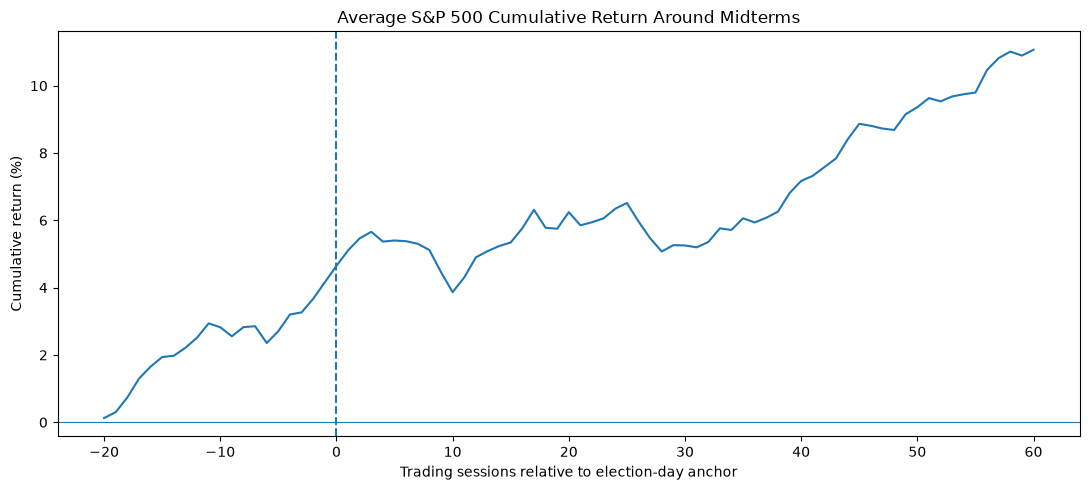

Elections included: 16
Mean cumulative return at +5 sessions: 5.4 %
Mean cumulative return at +20 sessions: 6.24 %
Mean cumulative return at +60 sessions: 11.07 %


In [52]:
paths = []

for _, election in elections.iterrows():
    d = election["election_date"]
    idx = spx["date"].searchsorted(d, side="right") - 1

    if idx < 21 or idx + 60 >= len(spx):
        continue

    # Day 0 is the last market session on/before Election Day.
    r = spx["log_return"].iloc[idx - 20:idx + 61].to_numpy()
    path = (np.exp(np.cumsum(r)) - 1) * 100
    paths.append(path)

paths = np.asarray(paths)
relative_days = np.arange(-20, 61)

plt.figure(figsize=(11, 5))
plt.plot(relative_days, paths.mean(axis=0))
plt.axvline(0, linestyle="--")
plt.axhline(0, linewidth=0.8)
plt.title("Average S&P 500 Cumulative Return Around Midterms")
plt.xlabel("Trading sessions relative to election-day anchor")
plt.ylabel("Cumulative return (%)")
plt.tight_layout()
plt.show()

print("Elections included:", len(paths))
print("Mean cumulative return at +5 sessions:", round(paths[:, 25].mean(), 2), "%")
print("Mean cumulative return at +20 sessions:", round(paths[:, 40].mean(), 2), "%")
print("Mean cumulative return at +60 sessions:", round(paths[:, 80].mean(), 2), "%")

A. Research question

Do U.S. equity markets exhibit distinctive return and volatility patterns before, during, and after U.S. midterm elections, and can those patterns help us form a probabilistic outlook for the 2026 midterms?

The primary index is the S&P 500, with the Dow Jones Industrial Average and Nasdaq Composite as robustness checks.

B. Major-section findings

Analysis	Main finding	Interpretation
Daily returns	Mean daily log returns: SPX 0.0288%, Dow 0.0294%, Nasdaq 0.0397%	All three indices have positive historical average daily returns.
Pre-election returns	SPX averaged about +4.10% to +4.16% over 20 sessions	The pre-election window appears unusually strong compared with ordinary windows in the initial comparison.
Election-day return	Mean about +0.44% in the initial S&P event study	The election-day move itself is much smaller than the cumulative pre-election and longer post-election returns.
Post-election returns	SPX: +0.72% over 5 sessions, +1.63% over 20, +6.22% over 60	Positive averages, but outcomes vary substantially across elections.
Return dispersion	SPX 60-session returns ranged from −6.02% to +14.60%	The historical average does not guarantee a positive result in the next cycle.
Volatility	SPX realized volatility was 5.48% pre-election over 20 sessions and 7.36% post-election over 60 sessions	These raw figures are not directly comparable because the windows differ in length.
Cross-index check	60-session averages: SPX +6.22%, Dow +5.18%, Nasdaq +9.23%	Positive average post-election returns appear across the indices, although Nasdaq coverage is shorter.
Positive outcomes	SPX was positive in 87.5% of 60-session post-election windows; Dow 81.2%; Nasdaq 92.3%	Encouraging descriptive frequencies, but based on only 16, 16, and 13 events, respectively.

C. The initial matched-window comparison

Your S&P 500 comparison produced:
Window	Midterm mean	Ordinary-window mean	Difference
Pre-election, 20 sessions	4.10%	0.62%	+3.48 percentage points
Post-election, 5 sessions	0.72%	0.16%	+0.55 pp
Post-election, 20 sessions	1.63%	0.64%	+0.99 pp
Post-election, 60 sessions	6.22%	1.53%	+4.69 pp

The initial permutation test reported p-values of 0.0004, 0.3136, 0.3538, and 0.0060, respectively. These are exploratory results, not final statistical evidence: the ordinary windows overlap each other, the market is serially dependent, and the event windows are few. We must not treat those p-values as conclusive.

D. A critical correction to the exploratory workflow

The average cumulative-path chart reported +5.40% at +5 sessions, +6.24% at +20, and +11.07% at +60. These values do not match the event-study averages, particularly the 60-session figure of +6.22%.

The path chart and event-study table use different anchoring and cumulative-return conventions. There is also a timing issue: the earlier event-study calculations used the last available market observation on or before Election Day, which can shift an election-day label when the election date is not a trading session.

Therefore:
- Keep the results as exploratory observations, not final estimates.
- Do not cite the cumulative-path values as verified findings yet.
- In the next notebook, define a single event-time convention and calculate all windows from it consistently.
- Recalculate final effect sizes and inference under that convention before writing the paper's results.

E. What we can and cannot conclude

What we can say: the sample shows positive average pre-election and 60-session post-election returns across several major U.S. equity indices. The pre-election and 60-session differences versus ordinary windows are promising research leads.

What we cannot yet say: that midterms reliably cause higher returns, that volatility necessarily declines after election uncertainty clears, or that the same average will occur in 2026.

The 2026 forecasting goal requires more than a historical average. We need to measure the uncertainty around the average, test it against appropriate comparison periods, assess whether results are driven by a few historical episodes, and eventually evaluate whether political outcomes add predictive information.